[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/multigeom/multigeom-tutorials/blob/main/notebooks/f1_what_one_response_tells_you.ipynb)

# What one response tells you

* **Author**: simone.azeglio@gmail.com

* **Goal**: Given one noisy response of a neuron, what can be said about the stimulus that caused it?

* **Needs**: a CPU, no data.

* **Time**: about 5 s.

* **Track**: Foundations, notebook 1. One neuron, a one-dimensional stimulus and every quantity computed exactly on a grid with `multigeom.lowdim`. The prior, the response distribution and the posterior are the starting objects of Section 2 of Azeglio, Laquitaine, Ferrari, Chalk (NeurIPS 2026, arXiv 2605.06304).

* **Next**: notebook f2 turns the posteriors of all responses into one number, the mutual information.

## 1. Setup

### 1.1. Install package

On Google Colab, install `multigeom`. Elsewhere this cell does nothing.

time: <1 sec

In [1]:
%%time

# on Google Colab install the package from PyPI, without its dependencies: Colab already
# has torch, numpy, scipy and matplotlib, and reinstalling torch is slow and can break
# the GPU runtime (nothing to do on your own machine)
import sys

if "google.colab" in sys.modules:
    %pip install -q --no-deps --pre multigeom

CPU times: user 5 μs, sys: 0 ns, total: 5 μs
Wall time: 6.91 μs


### 1.2. Imports

Import the packages, pick the device, compute in float64 and set the figure style. The device is `cuda` when there is a GPU and `cpu` otherwise, never `mps`, which has no float64.

time: 1 sec

In [2]:
%%time

import matplotlib.pyplot as plt
import torch

from multigeom.lowdim import posterior, response_density, response_grid

# run on the GPU when there is one
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_default_dtype(torch.float64)
print("device:", device)

# figure style of the Foundations notebooks: 9 pt text or more, no top or right spines
plt.rcParams.update(
    {
        "font.size": 10,
        "axes.labelsize": 10,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 9,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "legend.frameon": False,
    }
)
TEAL, ROSE, VIOLET, INK, GREY = "#2A8C7E", "#B23A62", "#5b3fd1", "#1a1a1a", "#8a8a8a"

device: cpu
CPU times: user 824 ms, sys: 183 ms, total: 1.01 s
Wall time: 1.71 s


### 1.3. Parameters of the series

These values are the same in every Foundations notebook. The stimulus $x$ lies on $[-3, 3]$, sampled on a grid of 1,201 points. The prior is uniform, $p(x) = 1/6$. The neuron has the bell-shaped tuning curve $f(x) = e^{-x^2/2}$, and its response is $r = f(x) + \sigma z$, with $z$ a standard Gaussian and $\sigma = 0.1$. A response is a firing rate in units of the peak rate.

The prior is normalised so that its Riemann sum on the grid is 1, the convention of `multigeom.lowdim`.

time: <1 sec

In [3]:
%%time

X_MIN, X_MAX = -3.0, 3.0  # stimulus range
N_X = 1201  # stimulus grid points (step 0.005)
SIGMA = 0.1  # standard deviation of the response noise

x = torch.linspace(X_MIN, X_MAX, N_X, device=device)
dx = (x[1] - x[0]).item()
prior = torch.ones_like(x) / (N_X * dx)  # uniform, sums to 1 on the grid


def bell(x):
    """Tuning curve of the bell-shaped neuron, f(x) = exp(-x^2 / 2)."""
    return torch.exp(-(x**2) / 2)


f = bell(x)
print(f"grid step {dx:.3f}, prior density {prior[0].item():.4f} (1/6 = {1 / 6:.4f})")

grid step 0.005, prior density 0.1665 (1/6 = 0.1667)
CPU times: user 429 μs, sys: 2 ms, total: 2.43 ms
Wall time: 13.9 ms


### 1.4. Custom functions

`bumps` finds the bumps of a density on the grid. For each bump it returns where the maximum is, the probability it holds and its half-width at half height. The half-width at half height is the distance from the maximum to the point where the density falls to half of its peak value, averaged over the two sides. Neighbouring bumps are split at the lowest point between them.

time: <1 sec

In [4]:
%%time


def bumps(x, density):
    """(location, mass, half-width at half height) of each bump of a density."""
    step = (x[1] - x[0]).item()
    is_peak = (density[1:-1] > density[:-2]) & (density[1:-1] >= density[2:])
    peaks = (torch.nonzero(is_peak).flatten() + 1).tolist()
    cuts = [0]
    for a, b in zip(peaks, peaks[1:]):
        cuts.append(a + int(torch.argmin(density[a:b])))
    cuts.append(len(density))
    out = []
    for peak, lo, hi in zip(peaks, cuts, cuts[1:]):
        part = density[lo:hi]
        n_above = (part >= density[peak] / 2).sum().item()
        location = round(x[peak].item(), 4) + 0.0  # + 0.0 turns -0.0 into 0.0
        out.append((location, part.sum().item() * step, n_above * step / 2))
    return out

CPU times: user 2 μs, sys: 0 ns, total: 2 μs
Wall time: 2.86 μs


## 2. From repeats to a distribution

We show the stimulus $x = -1$ many times. Each showing is one repeat, and each repeat gives one response $r$. We draw 5,000 responses with a fixed random generator and build histograms from the first 20, 200 and 5,000 of them.

Each histogram has bins of width 0.02 and is scaled as a density: the count in a bin divided by the number of repeats times the bin width. The area of each bar is then the share of repeats in that bin. The curve on top is the Gaussian density

$$\mathcal{N}(r;\, \mu,\, \sigma^2) = \frac{1}{\sqrt{2\pi}\,\sigma}\, \exp\!\left(-\frac{(r - \mu)^2}{2\sigma^2}\right),$$

with mean $\mu = f(-1) = 0.607$ and standard deviation $\sigma = 0.1$.

time: <1 sec

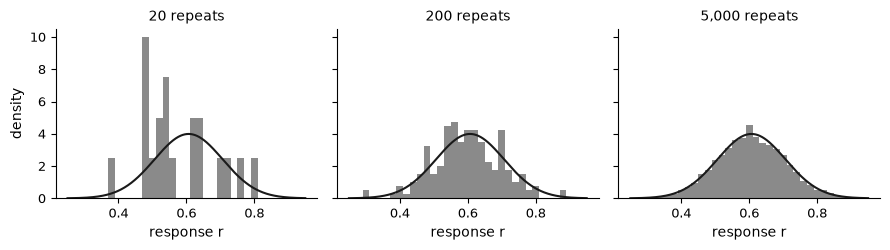

CPU times: user 110 ms, sys: 7.02 ms, total: 117 ms
Wall time: 132 ms


In [5]:
%%time

X_SHOWN = -1.0  # the stimulus shown in every repeat
REPEATS = (20, 200, 5000)
BIN = 0.02  # bin width of the histograms

generator = torch.Generator(device=device).manual_seed(0)
mean_shown = bell(torch.tensor(X_SHOWN)).item()
draws = mean_shown + SIGMA * torch.randn(
    REPEATS[-1], generator=generator, device=device
)

r_axis = torch.linspace(0.25, 0.95, 701)
curve = response_density(torch.tensor([mean_shown]), SIGMA, r_axis)[0]
edges = torch.arange(0.25, 0.95 + BIN / 2, BIN)

fig, axes = plt.subplots(1, 3, figsize=(9, 2.6), sharey=True)
for ax, n in zip(axes, REPEATS):
    sample = draws[:n].cpu()
    ax.hist(sample, bins=edges, weights=torch.full((n,), 1 / (n * BIN)), color=GREY)
    ax.plot(r_axis, curve, color=INK, lw=1.5)
    ax.set_xlabel("response r")
    ax.set_title(f"{n:,} repeats", fontsize=10)
axes[0].set_ylabel("density")
plt.tight_layout()
plt.show()

The 20 bars are ragged and the 5,000 bars follow the curve. The next cell checks the numbers that describe the density. Its peak value is $1/(\sqrt{2\pi}\,\sigma)$, which exceeds 1, because a density is not a probability. A Gaussian response lands within $\pm\sigma$ of the mean with probability 68.3%, and within $\pm 2\sigma$ with probability 95.4%.

time: <1 sec

In [6]:
%%time

peak_density = curve.max().item()
within_one_sigma = ((draws - mean_shown).abs() < SIGMA).double().mean().item()
expected_in_central_bin = {n: n * BIN * peak_density for n in (20, 5000)}

print(f"mean response f(-1)          {mean_shown:.3f}   (expected 0.607)")
print(f"peak of the density          {peak_density:.2f}    (expected 3.99)")
print(f"sample mean, 5,000 repeats   {draws.mean().item():.3f}")
print(f"sample sd, 5,000 repeats     {draws.std().item():.3f}   (sigma = {SIGMA})")
print(f"share within +-sigma         {within_one_sigma:.3f}   (exact 0.683)")
within_two_sigma = 2 * torch.special.ndtr(torch.tensor(2.0)).item() - 1
print(f"exact share within +-2 sigma {within_two_sigma:.3f}   (expected 0.954)")
for n, count in expected_in_central_bin.items():
    print(f"expected count, central bin, {n:,} repeats: {count:.1f}")

mean response f(-1)          0.607   (expected 0.607)
peak of the density          3.99    (expected 3.99)
sample mean, 5,000 repeats   0.605
sample sd, 5,000 repeats     0.100   (sigma = 0.1)
share within +-sigma         0.682   (exact 0.683)
exact share within +-2 sigma 0.954   (expected 0.954)
expected count, central bin, 20 repeats: 1.6
expected count, central bin, 5,000 repeats: 398.9
CPU times: user 395 μs, sys: 603 μs, total: 998 μs
Wall time: 3.25 ms


With 20 repeats the central bin expects 1.6 responses, which is why that histogram is ragged. With 5,000 repeats it expects about 400.

## 3. One distribution per stimulus

A different stimulus gives a different distribution of responses. The response distribution of $x$ is

$$p(r \mid x) = \mathcal{N}\big(r;\, f(x),\, \sigma^2\big),$$

and its mean, read as a function of the stimulus, is the tuning curve $f(x)$. The response distributions of all stimuli together are the neural code of the neuron. `response_density(f, sigma, r)` evaluates $p(r \mid x)$ on the stimulus grid and on a response grid, one row per stimulus.

The figure draws the code as a plane, shaded by $p(r \mid x)$, with the tuning curve on top. The right panel is the vertical cut at $x = -1$, the density of Section 2. The violet line marks the response $r = 0.6$, used in Section 5.

time: <1 sec

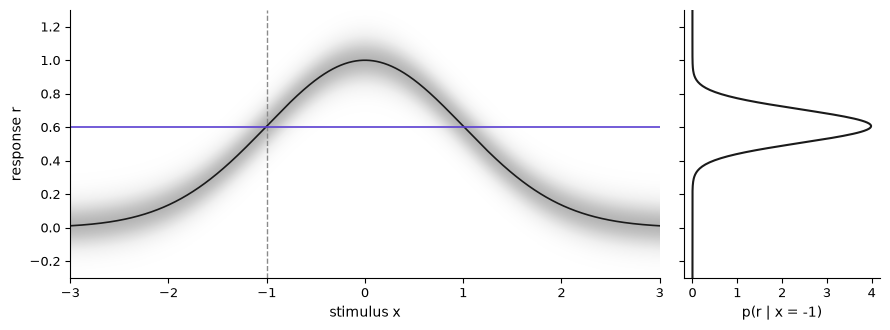

f(0) = 1.000
f(1) = 0.607
f(3) = 0.011
CPU times: user 86 ms, sys: 15.1 ms, total: 101 ms
Wall time: 109 ms


In [7]:
%%time

r = response_grid(f, SIGMA, n_r=361)  # covers f(x) +- 6 sigma
code = response_density(f, SIGMA, r)  # p(r | x), [N_X, 361]
i_shown = torch.argmin((x - X_SHOWN).abs())

fig, (ax, ax_cut) = plt.subplots(
    1, 2, figsize=(9, 3.4), sharey=True, gridspec_kw={"width_ratios": [3, 1]}
)
extent = (X_MIN, X_MAX, r[0].item(), r[-1].item())
shade = dict(origin="lower", extent=extent, aspect="auto", cmap="Greys")
ax.imshow(code.T.cpu(), vmax=2.5 * code.max().item(), **shade)
ax.plot(x.cpu(), f.cpu(), color=INK, lw=1.2)
ax.axvline(X_SHOWN, color=GREY, ls="--", lw=1)
ax.axhline(0.6, color=VIOLET, lw=1.2)
ax.set_xlabel("stimulus x")
ax.set_ylabel("response r")
ax.set_ylim(-0.3, 1.3)
ax_cut.plot(code[i_shown].cpu(), r.cpu(), color=INK)
ax_cut.set_xlabel("p(r | x = -1)")
plt.tight_layout()
plt.show()

for value in (0.0, 1.0, 3.0):
    print(f"f({value:.0f}) = {bell(torch.tensor(value)).item():.3f}")

The tuning curve equals 1 at the preferred stimulus $x = 0$, 0.61 at $x = \pm 1$ and 0.01 at $x = \pm 3$.

## 4. The prior, the joint density and the marginal

The prior $p(x)$ says how often each stimulus occurs before any response is seen. Ours is uniform on $[-3, 3]$. The product rule gives the joint density of a stimulus and a response, and the sum rule gives the marginal density of the responses alone:

$$p(x, r) = p(r \mid x)\, p(x), \qquad p(r) = \int p(r \mid x)\, p(x)\, dx .$$

On the grid the integral is a Riemann sum over the stimuli.

time: <1 sec

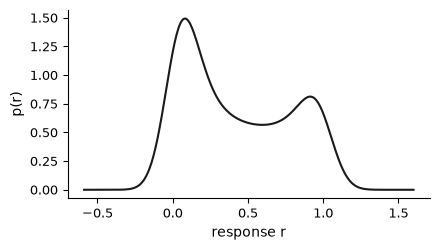

area under p(r)              1.0000
p(r) is highest at r = 0.08, value 1.49   (expected 0.08 and 1.49)
share of stimuli with f(x) < 0.1: 0.285   (expected 0.285)
CPU times: user 31 ms, sys: 2.66 ms, total: 33.6 ms
Wall time: 33.9 ms


In [8]:
%%time

joint = code * prior[:, None]  # p(x, r)
marginal = joint.sum(0) * dx  # p(r)
dr = (r[1] - r[0]).item()

i_max = torch.argmax(marginal)
marginal_peak_r, marginal_peak = r[i_max].item(), marginal[i_max].item()
share_below_tenth = (prior * (f < 0.1)).sum().item() * dx

fig, ax = plt.subplots(figsize=(4.5, 2.6))
ax.plot(r.cpu(), marginal.cpu(), color=INK)
ax.set_xlabel("response r")
ax.set_ylabel("p(r)")
plt.tight_layout()
plt.show()

print(f"area under p(r)              {marginal.sum().item() * dr:.4f}")
print(
    f"p(r) is highest at r = {marginal_peak_r:.2f}, value {marginal_peak:.2f}"
    "   (expected 0.08 and 1.49)"
)
print(f"share of stimuli with f(x) < 0.1: {share_below_tenth:.3f}   (expected 0.285)")

The marginal is highest near $r = 0.08$, because 28.5% of the stimuli lie far enough from the peak to have mean responses below 0.1.

## 5. Bayes' rule

The brain receives a response and has to infer the stimulus. Bayes' rule turns the response distribution into the posterior, the density of the stimulus given the observed response:

$$p(x \mid r) = \frac{p(r \mid x)\, p(x)}{p(r)} .$$

The response distribution evaluated at the observed $r$, read as a function of $x$, is the likelihood. With a uniform prior the posterior has the shape of the likelihood, normalised to area 1. `posterior(x, f, prior, sigma, r)` returns one density over the stimulus grid per response. We compute it for the responses 0.3, 0.6 and 1.0.

time: <1 sec

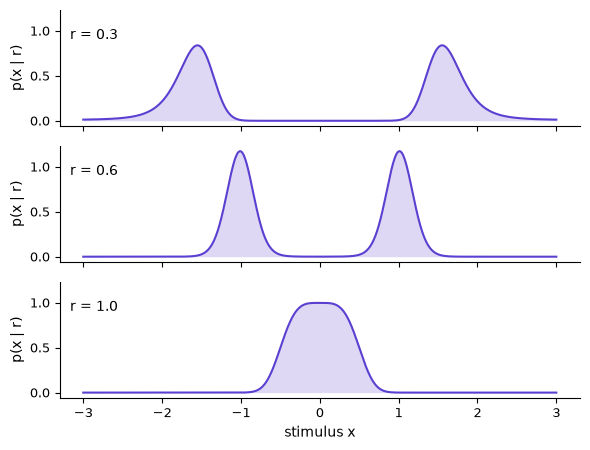

CPU times: user 84.9 ms, sys: 4.36 ms, total: 89.3 ms
Wall time: 96.2 ms


In [9]:
%%time

RESPONSES = (0.3, 0.6, 1.0)
posteriors = posterior(x, f, prior, SIGMA, torch.tensor(RESPONSES))  # [N_X, 3]

fig, axes = plt.subplots(3, 1, figsize=(6, 4.6), sharex=True, sharey=True)
for ax, r_obs, density in zip(axes, RESPONSES, posteriors.T.cpu()):
    ax.fill_between(x.cpu(), density, color=VIOLET, alpha=0.2, lw=0)
    ax.plot(x.cpu(), density, color=VIOLET)
    ax.text(0.02, 0.75, f"r = {r_obs}", transform=ax.transAxes)
    ax.set_ylabel("p(x | r)")
axes[-1].set_xlabel("stimulus x")
plt.tight_layout()
plt.show()

For $r = 0.6$ the posterior has two bumps, one on each side of the peak of the tuning curve. They sit where the tuning curve passes through the response, and the bell-shaped curve does this twice. The next cell measures each bump with `bumps`.

time: <1 sec

In [10]:
%%time

posterior_bumps = {
    r_obs: bumps(x, posteriors[:, k]) for k, r_obs in enumerate(RESPONSES)
}

print("response   location   mass   half-width at half height")
for r_obs, found in posterior_bumps.items():
    for location, mass, half_width in found:
        print(f"  {r_obs:.1f}      {location:+.2f}     {mass:.3f}   {half_width:.2f}")
print("expected: 0.3 -> +-1.55, 0.26 | 0.6 -> +-1.01, half each, 0.20 | 1.0 -> 0, 0.50")

response   location   mass   half-width at half height
  0.3      -1.55     0.500   0.26
  0.3      +1.55     0.500   0.26
  0.6      -1.01     0.500   0.20
  0.6      +1.01     0.500   0.20
  1.0      +0.00     1.000   0.50
expected: 0.3 -> +-1.55, 0.26 | 0.6 -> +-1.01, half each, 0.20 | 1.0 -> 0, 0.50
CPU times: user 546 μs, sys: 542 μs, total: 1.09 ms
Wall time: 3.46 ms


The response 0.6 gives two bumps at $x = \pm 1.01$, each holding half of the posterior, with a half-width at half height of 0.20. The response 0.3 gives wider bumps at $\pm 1.55$, and the response 1.0 gives one broad bump centred on the peak.

Two numbers explain these widths. The bumps for 0.3 are wider because the tuning curve is flatter there, with a slope $\lvert f'(x) \rvert = \lvert x \rvert e^{-x^2/2}$ of 0.47 at $x = 1.55$ against 0.61 at $x = 1.01$. Stimuli near the peak are almost excluded for $r = 0.6$: their mean response 1 lies four noise standard deviations away from 0.6.

time: <1 sec

In [11]:
%%time


def slope(value):
    """|f'(x)| of the bell-shaped neuron."""
    return abs(value) * bell(torch.tensor(value)).item()


i_zero = torch.argmin(x.abs())
post_06 = posteriors[:, 1]
likelihood_ratio = (post_06[i_zero] / post_06.max()).item()

print(f"slope at x = 1.55: {slope(1.55):.2f}   (expected 0.47)")
print(f"slope at x = 1.01: {slope(1.01):.2f}   (expected 0.61)")
print(
    f"posterior at x = 0 over its maximum: {likelihood_ratio:.1e}   (expected 3.4e-4)"
)

slope at x = 1.55: 0.47   (expected 0.47)
slope at x = 1.01: 0.61   (expected 0.61)
posterior at x = 0 over its maximum: 3.4e-04   (expected 3.4e-4)
CPU times: user 359 μs, sys: 212 μs, total: 571 μs
Wall time: 784 μs


## 6. Try it

Three changes to make, each in the cells of this notebook.

* Replace the bell-shaped tuning curve by the sigmoid $1/(1 + e^{-x})$, which only rises. Look at the number of bumps of the posterior for $r = 0.6$.
* Double the noise to $\sigma = 0.2$ in Section 1.3. Look at the widths of the bumps, which grow, and at the bump for $r = 1.0$.
* Use a prior that is not uniform, for example a Gaussian with standard deviation 1. Look at how it shifts the posterior towards the stimuli that occur more often.

The next cell carries out the first change. The sigmoid passes through 0.6 once, at $x = \ln(0.6/0.4) = 0.41$, so the posterior has a single bump there.

time: <1 sec

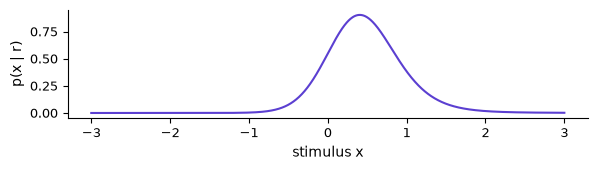

one bump at x = 0.405, mass 1.000, half-width 0.50
CPU times: user 30.4 ms, sys: 1.68 ms, total: 32.1 ms
Wall time: 32.2 ms


In [12]:
%%time

sigmoid = 1 / (1 + torch.exp(-x))
posterior_sigmoid = posterior(x, sigmoid, prior, SIGMA, torch.tensor([0.6]))[:, 0]
sigmoid_bumps = bumps(x, posterior_sigmoid)

fig, ax = plt.subplots(figsize=(6, 1.8))
ax.plot(x.cpu(), posterior_sigmoid.cpu(), color=VIOLET)
ax.set_xlabel("stimulus x")
ax.set_ylabel("p(x | r)")
plt.tight_layout()
plt.show()

for location, mass, half_width in sigmoid_bumps:
    print(
        f"one bump at x = {location:.3f}, mass {mass:.3f}, half-width {half_width:.2f}"
    )

**Next**: [notebook f2](f2_entropy_and_mutual_information.ipynb) measures, in bits, how much one response and all responses tell about the stimulus.